# Chapter 13: The Neyman–Pearson Lemma and Most Powerful Tests

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch13/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ibrahimguney/statistical-theory/blob/main/notebooks/ch_13.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## Power of the Test for a Normal Mean

*Source file:* `code/ch13/c13_1_power_normal_mean_test.py`

In [2]:
import numpy as np
import scipy.stats as stats

rng = np.random.default_rng(42)
s_h0 = rng.normal(0.0, 2.0, size=(150_000, 16))
s_h1 = rng.normal(1.0, 2.0, size=(150_000, 16))
c = stats.norm.ppf(0.95) * (2.0 / np.sqrt(16))
print(f"Critical value c = {c:.4f}")
print(f"Type I error (MC): {np.mean(np.mean(s_h0, axis=1) > c):.4f}  (target 0.05)")
print(f"Neyman-Pearson power: {np.mean(np.mean(s_h1, axis=1) > c):.4f}")
print(f"Analytic power       : {1 - stats.norm.cdf(stats.norm.ppf(0.95) - np.sqrt(16)*1.0/2.0):.4f}")
za, zb = stats.norm.ppf(0.95), stats.norm.ppf(0.80)
print(f"Required n for power 0.80 = {((za + zb) * 2.0 / 1.0)**2:.2f}")

Critical value c = 0.8224
Type I error (MC): 0.0497  (target 0.05)
Neyman-Pearson power: 0.6397
Analytic power       : 0.6388
Required n for power 0.80 = 24.73


## A Randomised Poisson Test

*Source file:* `code/ch13/c13_2_randomised_poisson_test.py`

In [3]:
import numpy as np
from scipy import stats

alpha, n, l0, l1 = 0.05, 10, 1.0, 2.0
T0, T1 = stats.poisson(n*l0), stats.poisson(n*l1)
c = int(T0.ppf(1 - alpha))            # smallest c: P0(T > c) <= alpha
while T0.sf(c) > alpha: c += 1
gamma = (alpha - T0.sf(c)) / T0.pmf(c)
print(f"Reject: T > {c} ; if T = {c} reject with probability gamma = {gamma:.4f}")
print(f"P0(T >= {c+1}) = {T0.sf(c):.4f} | P0(T >= {c}) = {T0.sf(c-1):.4f}")
print(f"Size = {T0.sf(c) + gamma*T0.pmf(c):.4f}")
print(f"Power (randomised)        = {T1.sf(c) + gamma*T1.pmf(c):.4f}")
print(f"Power (T > {c}, conservative) = {T1.sf(c):.4f}")

rng = np.random.default_rng(42)
T = rng.poisson(n*l1, size=1_000_000)
rej = (T > c) | ((T == c) & (rng.random(T.size) < gamma))
print(f"Power (simulation)        = {rej.mean():.4f}")

Reject: T > 15 ; if T = 15 reject with probability gamma = 0.0363
P0(T >= 16) = 0.0487 | P0(T >= 15) = 0.0835
Size = 0.0500
Power (randomised)        = 0.8454
Power (T > 15, conservative) = 0.8435
Power (simulation)        = 0.8452


## Power Curves and the Distribution of $p$-Values

*Source file:* `code/ch13/c13_3_power_curves_pvalue_distribution.py`

mu=0.0: P(p <= 0.05) = 0.0503
mu=0.5: P(p <= 0.05) = 0.2606


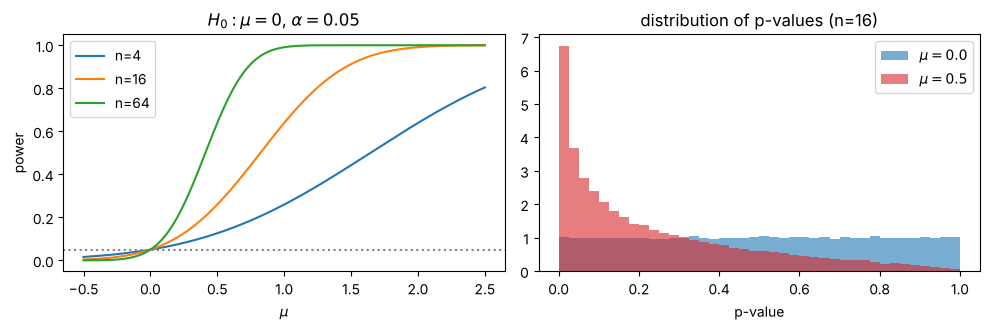

In [4]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
sigma, za = 2.0, stats.norm.ppf(0.95)
mu = np.linspace(-0.5, 2.5, 300)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for n in [4, 16, 64]:
    ax[0].plot(mu, 1 - stats.norm.cdf(za - np.sqrt(n)*mu/sigma), label=f"n={n}")
ax[0].axhline(0.05, color="gray", ls=":"); ax[0].set_xlabel(r"$\mu$"); ax[0].set_ylabel("power")
ax[0].set_title(r"$H_0:\mu=0$, $\alpha=0.05$"); ax[0].legend()

for mu1, col in [(0.0, "tab:blue"), (0.5, "tab:red")]:
    xb = rng.normal(mu1, sigma/4, size=100_000)
    p = 1 - stats.norm.cdf(xb / (sigma/4))
    ax[1].hist(p, bins=40, range=(0, 1), density=True, alpha=0.6, color=col, label=rf"$\mu={mu1}$")
    print(f"mu={mu1}: P(p <= 0.05) = {np.mean(p <= 0.05):.4f}")
ax[1].set_xlabel("p-value"); ax[1].set_title("distribution of p-values (n=16)"); ax[1].legend()
fig.tight_layout(); fig.savefig("guc_pdeger.pdf")